In [1]:
import os
import requests
import pandas as pd
import sqlite3
from dotenv import load_dotenv

pd.set_option("display.max_columns", None)

In [2]:
conn = sqlite3.connect("movies.db")

# List all tables
pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table';", conn)

,name
0,genres
1,movies
2,movie_genres
3,daily_snapshots
4,omdb_ratings


In [3]:
# Look at a table
movies = pd.read_sql_query("SELECT * FROM movies LIMIT 10;", conn)
movies

,tmdb_id,imdb_id,title,release_date,runtime_min,budget_usd,revenue_usd,original_language,added_on
0,453,tt0268978,A Beautiful Mind,2001-12-14,136,58000000,316791257,en,2026-11-22
1,483,tt0100935,Wild at Heart,1990-08-17,125,9500000,14569027,en,2026-11-22
2,752,tt0434409,V for Vendetta,2006-02-23,132,54000000,134686457,en,2026-11-22
3,1255,tt0468492,The Host,2006-07-27,120,11000000,88489643,ko,2026-11-22
4,1359,tt0144084,American Psycho,2000-04-13,102,7000000,34269748,en,2026-11-22
5,1366,tt0075148,Rocky,1976-12-03,119,970000,117253345,en,2026-11-22
6,1887,tt0422720,Marie Antoinette,2006-05-24,123,40000000,60917189,en,2026-11-22
7,2034,tt0139654,Training Day,2001-10-05,122,45000000,104900000,en,2026-11-22
8,8913,tt0098084,Pet Sematary,1989-04-21,103,11500000,57500000,en,2026-11-22
9,9495,tt0109506,The Crow,1994-05-11,102,23000000,93722164,en,2026-11-22


In [4]:
# genres
genres = pd.read_sql_query("SELECT * FROM genres;", conn)
genres

,genre_id,name
0,12,Adventure
1,14,Fantasy
2,16,Animation
3,18,Drama
4,27,Horror
5,28,Action
6,35,Comedy
7,36,History
8,37,Western
9,53,Thriller


In [5]:
# genres
movie_genres = pd.read_sql_query("SELECT * FROM movie_genres LIMIT 10;", conn)
movie_genres

,tmdb_id,genre_id
0,1300968,878
1,1300968,28
2,1300968,12
3,1368337,12
4,1368337,28
5,1368337,14
6,1003596,878
7,1003596,28
8,1003596,12
9,1595124,16


In [6]:

ds = pd.read_sql_query("SELECT * FROM daily_snapshots LIMIT 10;", conn)
ds

,snapshot_date,list_type,rank,tmdb_id,popularity,vote_average,vote_count
0,2026-11-22,trending,1,1300968,383.3057,7.792,248
1,2026-11-22,trending,2,1368337,499.7136,8.023,5385
2,2026-11-22,trending,3,1003596,162.6042,0.000,0
3,2026-11-22,trending,4,1595124,99.4839,6.851,57
4,2026-11-22,trending,5,1599184,148.1282,9.400,5
5,2026-11-22,trending,6,969681,310.0185,8.458,7060
6,2026-11-22,trending,7,1568060,88.7474,7.300,28
7,2026-11-22,trending,8,1381071,110.8891,7.687,292
8,2026-11-22,trending,9,1551025,181.6675,6.980,100
9,2026-11-22,trending,10,1423191,288.2852,7.523,2501


In [7]:

ratings = pd.read_sql_query("SELECT * FROM omdb_ratings LIMIT 10;", conn)
ratings

,imdb_id,imdb_rating,imdb_votes,rotten_tomatoes_pct,metascore,box_office_usd,rated,awards,fetched_on
0,tt11995650,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-11-22
1,tt13611778,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-11-22
2,tt14129116,NaN,NaN,NaN,NaN,NaN,R,NaN,2026-11-22
3,tt14413964,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-11-22
4,tt15239678,8.4,797737.0,92.0,79.0,282144358.0,PG-13,Won 2 Oscars. 126 wins & 375 nominations total,2026-11-22
5,tt15799564,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-11-22
6,tt18351090,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-11-22
7,tt2056785,8.7,15186.0,NaN,88.0,25896210.0,PG-13,1 win total,2026-11-22
8,tt21357150,NaN,NaN,NaN,NaN,NaN,NaN,2 nominations total,2026-11-22
9,tt22084616,8.0,327986.0,NaN,66.0,954994964.0,PG-13,1 nomination total,2026-11-22


In [8]:
! pip install matplotlib


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [9]:
import matplotlib.pyplot as plt

# All movies with OMDb ratings (no LIMIT this time)
ratings = pd.read_sql_query("""
    SELECT m.title, m.release_date,
           o.imdb_rating, o.imdb_votes, o.rotten_tomatoes_pct
    FROM omdb_ratings o
    JOIN movies m USING (imdb_id)
""", conn)

# How much data is there?
print(f"Movies with OMDb rows:      {len(ratings)}")
print(f"Have IMDb rating:           {ratings['imdb_rating'].notna().sum()}")
print(f"Have Rotten Tomatoes score: {ratings['rotten_tomatoes_pct'].notna().sum()}")

both = ratings.dropna(subset=["imdb_rating", "rotten_tomatoes_pct"]).copy()
both["imdb_100"] = both["imdb_rating"] * 10                    # put on 0-100 scale
both["gap"] = both["rotten_tomatoes_pct"] - both["imdb_100"]   # + = critics liked it more
print(f"Have both:                  {len(both)}")
both.sort_values("gap")

Movies with OMDb rows:      173
Have IMDb rating:           81
Have Rotten Tomatoes score: 25
Have both:                  22


,title,release_date,imdb_rating,imdb_votes,rotten_tomatoes_pct,imdb_100,gap
109,Michael,2026-04-22,7.3,199903.0,38.0,73.0,-35.0
128,The Devils,1971-07-16,7.8,26363.0,55.0,78.0,-23.0
52,The Angry Birds Movie,2016-05-11,6.3,122214.0,44.0,63.0,-19.0
118,In the Grey,2026-05-13,6.3,52226.0,53.0,63.0,-10.0
66,Pet Sematary,1989-04-21,6.5,125816.0,55.0,65.0,-10.0
111,V for Vendetta,2006-02-23,8.1,1258015.0,73.0,81.0,-8.0
68,A Beautiful Mind,2001-12-14,8.2,1065553.0,74.0,82.0,-8.0
132,Marie Antoinette,2006-05-24,6.5,133928.0,58.0,65.0,-7.0
107,American Psycho,2000-04-13,7.6,859346.0,69.0,76.0,-7.0
138,Wild at Heart,1990-08-17,7.2,113444.0,66.0,72.0,-6.0


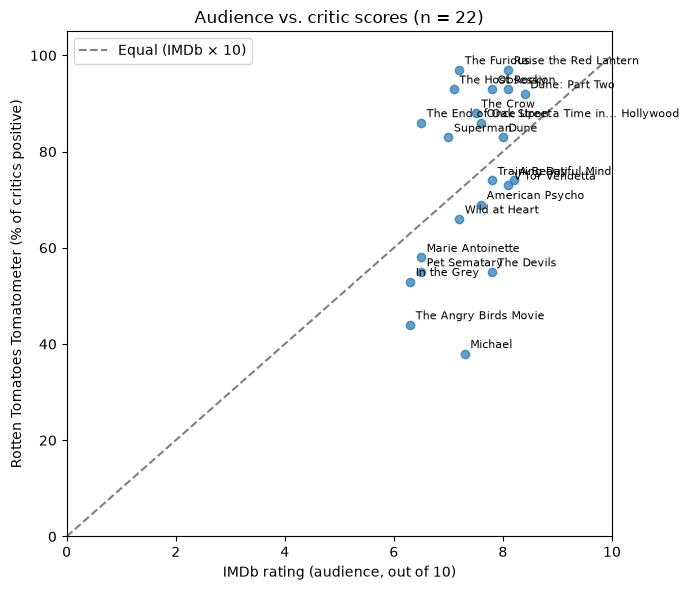

In [10]:
# Scatter: IMDb (audience) vs Rotten Tomatoes (critics)
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(both["imdb_rating"], both["rotten_tomatoes_pct"], alpha=0.7)

# Label each movie if there aren't too many
if len(both) <= 25:
    for _, r in both.iterrows():
        ax.annotate(r["title"], (r["imdb_rating"], r["rotten_tomatoes_pct"]),
                    fontsize=8, xytext=(4, 4), textcoords="offset points")

# Reference line where critics and audiences "agree" (e.g. 8.0 IMDb = 80%)
ax.plot([0, 10], [0, 100], "--", color="gray", label="Equal (IMDb × 10)")
ax.set_xlim(0, 10); ax.set_ylim(0, 105)
ax.set_xlabel("IMDb rating (audience, out of 10)")
ax.set_ylabel("Rotten Tomatoes Tomatometer (% of critics positive)")
ax.set_title(f"Audience vs. critic scores (n = {len(both)})")
ax.legend()
plt.tight_layout()
plt.show()

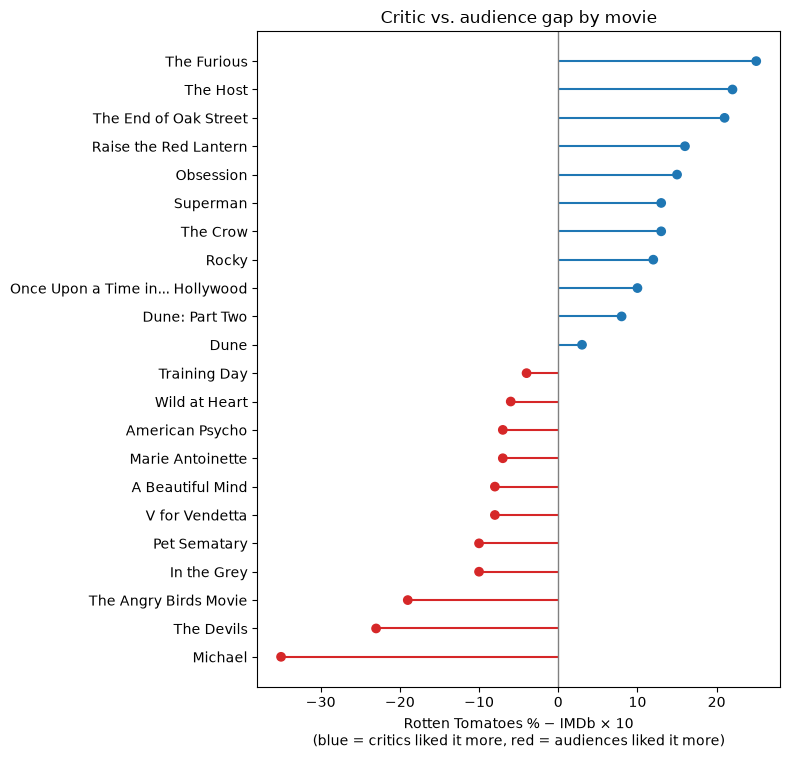

In [11]:
# Which movies do critics and audiences disagree on most?
gaps = both.sort_values("gap")
fig, ax = plt.subplots(figsize=(8, max(3, 0.35 * len(gaps))))
colors = ["tab:red" if g < 0 else "tab:blue" for g in gaps["gap"]]
ax.hlines(gaps["title"], 0, gaps["gap"], color=colors)
ax.scatter(gaps["gap"], gaps["title"], color=colors)
ax.axvline(0, color="gray", lw=1)
ax.set_xlabel("Rotten Tomatoes % − IMDb × 10\n(blue = critics liked it more, red = audiences liked it more)")
ax.set_title("Critic vs. audience gap by movie")
plt.tight_layout()
plt.show()